# 02 · Pruebas de variables, tests y gráficos
Banco de pruebas de las funciones de `src/utils` antes de llevarlas a la memoria.

In [1]:
import sys, warnings
sys.path.append("..")          # para poder importar src/utils desde src/notebooks
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
DATA_DIR = "../data"
from utils.data_cleaning import *
from utils.features import *
from utils import stats_tests as st, plots as pl
pl.configurar_estilo()

In [2]:
c, r = cargar_datos_brutos(DATA_DIR)
df = construir_dataset_analitico(limpiar_companies(c), limpiar_rounds(r))
df.shape

(66367, 35)

¿Qué año de corte elijo para la cohorte madura? Pruebo varios.

In [3]:
for corte in [2008, 2009, 2010, 2011, 2012]:
    m = df[(df['año_primera_financiacion'] <= corte) & df['funding_total_usd'].notna()]
    t = st.tasas_por_grupo(m, 'tramo_financiacion')
    print(corte, len(m), t['tasa_exito'].round(1).tolist(), t['tasa_cerrada'].round(1).tolist())

2008 11585 [8.3, 13.6, 24.3, 37.2, 41.6] [27.4, 23.0, 18.5, 13.2, 9.1]
2009 15050 [7.1, 12.2, 22.5, 35.1, 40.5] [23.0, 19.3, 16.8, 12.5, 8.2]
2010 19382 [6.5, 11.7, 20.8, 32.9, 38.4] [21.5, 17.6, 14.8, 11.5, 7.3]
2011 24426 [5.5, 11.2, 19.4, 30.2, 36.0] [19.7, 15.4, 13.3, 10.4, 6.7]
2012 30504 [4.3, 10.2, 17.6, 28.1, 34.0] [17.0, 13.7, 11.7, 9.6, 6.3]


El patrón es el mismo con cualquier corte → la conclusión es robusta. Elijo 2010 (≥ 5 años de recorrido y casi 20.000 startups).

In [4]:
m = df[df['cohorte_madura'] & df['funding_total_usd'].notna()]
st.chi_cuadrado(m, 'tramo_financiacion', 'resultado')

{'chi2': np.float64(1329.9),
 'p_valor': np.float64(8.098267442381605e-282),
 'grados_libertad': 8,
 'v_cramer': np.float64(0.185),
 'n': 19382,
 'significativo': np.True_}

Pruebo tramos por cuantiles en lugar de tramos fijos:

In [5]:
m2 = m.assign(q=pd.qcut(m['funding_total_usd'], 10))
st.tasas_por_grupo(m2, 'q')[['q', 'n', 'tasa_exito', 'tasa_cerrada']]

,q,n,tasa_exito,tasa_cerrada
0,"(1.999, 295304.4]",1939,5.72,22.33
1,"(295304.4, 1000000.0]",2095,10.31,19.19
2,"(1000000.0, 2192615.3]",1781,14.26,16.28
3,"(2192615.3, 4197000.0]",1938,17.18,14.24
4,"(4197000.0, 7000000.0]",2005,22.14,15.86
5,"(7000000.0, 11132000.0]",1871,26.78,12.93
6,"(11132000.0, 18500000.0]",1958,31.46,12.56
7,"(18500000.0, 31000000.0]",1937,34.54,10.58
8,"(31000000.0, 61245813.1]",1919,34.86,10.16
9,"(61245813.1, 30079503000.0]",1939,38.89,6.65


¿Se mantiene el efecto excluyendo EE. UU.?

In [6]:
st.tasas_por_grupo(m[m['country_code'] != 'USA'], 'tramo_financiacion')[['tramo_financiacion', 'n', 'tasa_exito', 'tasa_cerrada']]

,tramo_financiacion,n,tasa_exito,tasa_cerrada
0,"< 0,5 M$",1083,5.26,24.93
1,"0,5–2 M$",1180,8.47,18.73
2,2–10 M$,2032,14.52,15.50
3,10–50 M$,1667,22.80,14.34
4,> 50 M$,570,29.12,9.65


Importe de la primera ronda vs resultado (¿importa empezar fuerte?)

In [7]:
m3 = m.dropna(subset=['importe_primera_ronda']).assign(q1=lambda d: pd.qcut(d['importe_primera_ronda'], 5))
st.tasas_por_grupo(m3, 'q1')[['q1', 'n', 'tasa_exito', 'tasa_cerrada']]

,q1,n,tasa_exito,tasa_cerrada
0,"(-0.001, 500000.0]",4237,10.29,17.70
1,"(500000.0, 1800000.0]",3527,16.47,13.69
2,"(1800000.0, 5000000.0]",4375,23.73,12.94
3,"(5000000.0, 11000000.0]",3458,32.39,12.35
4,"(11000000.0, 17600000000.0]",3785,36.78,13.47


Prueba de gráficos:

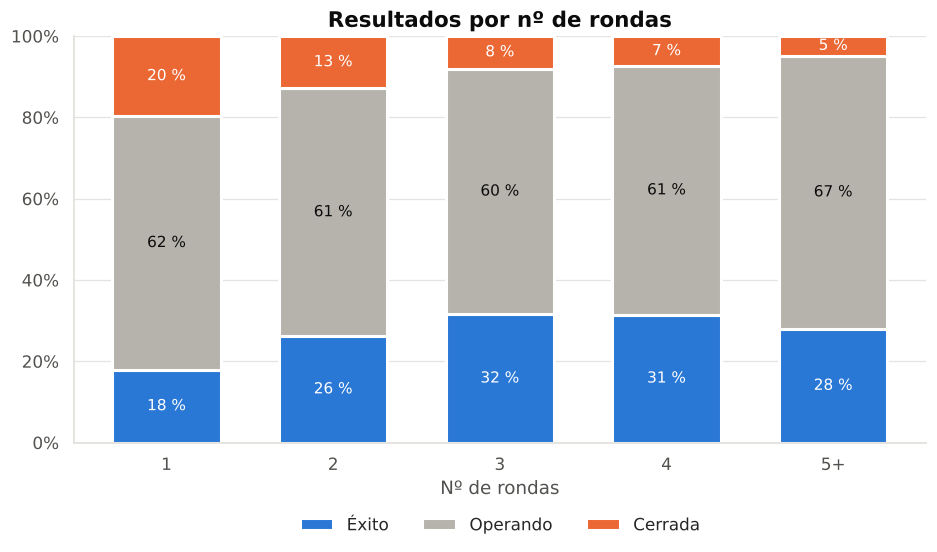

In [8]:
fig = pl.grafico_resultado_apilado(m, 'rondas_grupo', 'Resultados por nº de rondas', 'Nº de rondas'); plt.show()

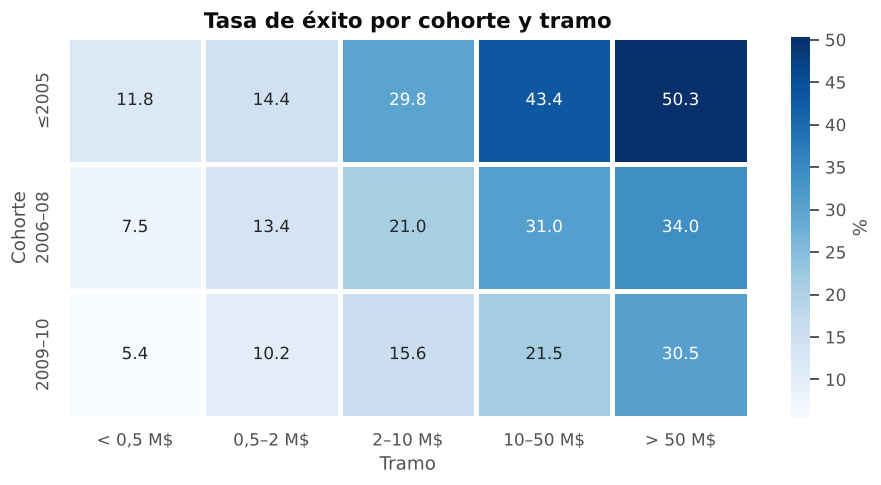

In [9]:
fig = pl.grafico_heatmap(m, 'cohorte', 'tramo_financiacion', 'exito', 'Tasa de éxito por cohorte y tramo', 'Tramo', 'Cohorte'); plt.show()

España (curiosidad para la presentación):

In [10]:
esp = df[df['country_code'] == 'ESP']
print(len(esp)); esp['resultado'].value_counts(normalize=True).mul(100).round(1), esp['funding_total_usd'].median()

746


(resultado
 Operando    87.4
 Cerrada      7.8
 Éxito        4.8
 Name: proportion, dtype: float64,
 np.float64(638871.5))